In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

image = data.camera().astype(np.uint8)
print("Image shape:", image.shape, "| dtype:", image.dtype)

Image shape: (512, 512) | dtype: uint8


## 2. Edge detectors
DoG and LoG are computed in floating point so that the sign of the response is kept (an 8-bit subtraction would clip negative values). The LoG magnitude is displayed, and zero-crossings (the classical LoG edge definition) are also extracted.

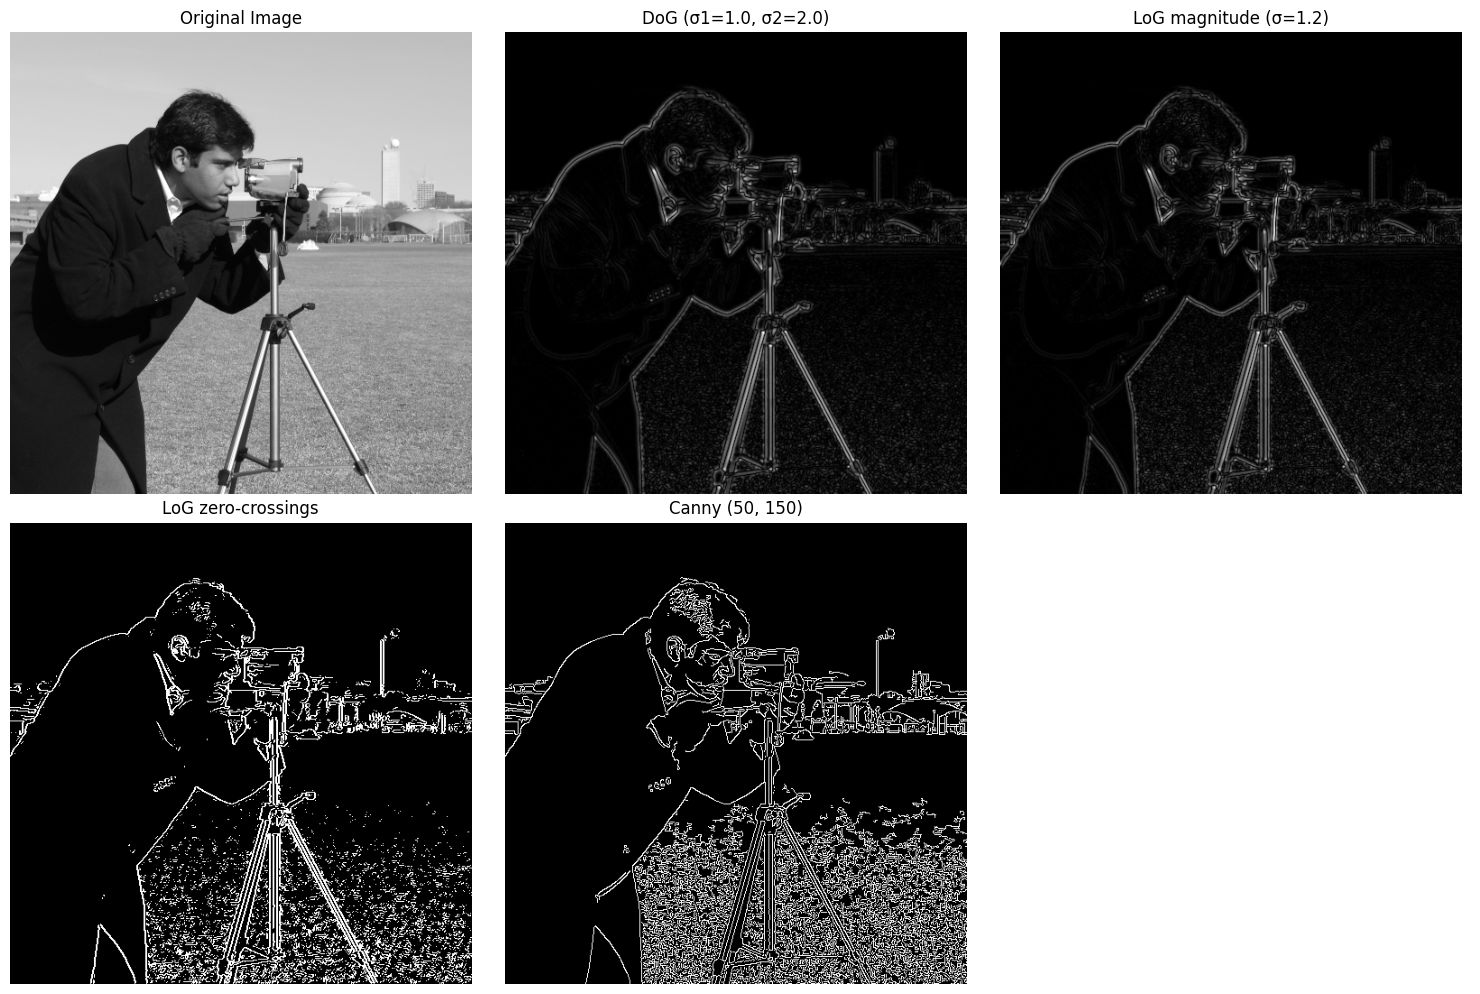

In [2]:
def dog_response(img, s1, s2):
    """Difference of Gaussians: G(s2)*I - G(s1)*I (float, signed)."""
    f = img.astype(np.float32)
    g1 = cv2.GaussianBlur(f, (0, 0), s1)
    g2 = cv2.GaussianBlur(f, (0, 0), s2)
    return g1 - g2

def log_response(img, sigma):
    """Laplacian of Gaussian: Laplacian applied to the Gaussian-smoothed image (float, signed)."""
    blur = cv2.GaussianBlur(img.astype(np.float32), (0, 0), sigma)
    return cv2.Laplacian(blur, cv2.CV_32F, ksize=3)

def zero_crossings(resp, min_strength):
    """Pixels where the response changes sign between neighbours and the jump is strong enough."""
    r = resp
    edges = np.zeros(r.shape, dtype=np.uint8)
    for dy, dx in [(0, 1), (1, 0), (1, 1), (1, -1)]:
        a = r[max(0, -dy):r.shape[0] - max(0, dy), max(0, -dx):r.shape[1] - max(0, dx)]
        b = np.roll(np.roll(r, -dy, axis=0), -dx, axis=1)[max(0, -dy):r.shape[0] - max(0, dy), max(0, -dx):r.shape[1] - max(0, dx)]
        cond = (a * b < 0) & (np.abs(a - b) > min_strength)
        edges[max(0, -dy):r.shape[0] - max(0, dy), max(0, -dx):r.shape[1] - max(0, dx)][cond] = 255
    return edges

def norm8(x):
    return cv2.normalize(np.abs(x), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# --- Parameters from the lab sheet ---
sigma1, sigma2 = 1.0, 2.0
sigma_log = 1.2
low_t, high_t = 50, 150

dog = dog_response(image, sigma1, sigma2)
log = log_response(image, sigma_log)
log_zc = zero_crossings(log, min_strength=np.percentile(np.abs(log), 90))
canny = cv2.Canny(image, low_t, high_t)

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
panels = [(image, "Original Image"), (norm8(dog), f"DoG (σ1={sigma1}, σ2={sigma2})"),
          (norm8(log), f"LoG magnitude (σ={sigma_log})"), (log_zc, "LoG zero-crossings"),
          (canny, f"Canny ({low_t}, {high_t})"), (None, "")]
for a, (im, t) in zip(ax.ravel(), panels):
    a.axis("off")
    if im is not None:
        a.imshow(im, cmap="gray"); a.set_title(t)
plt.tight_layout(); plt.show()

## 3. Parameter study (Student Tasks 1–3)

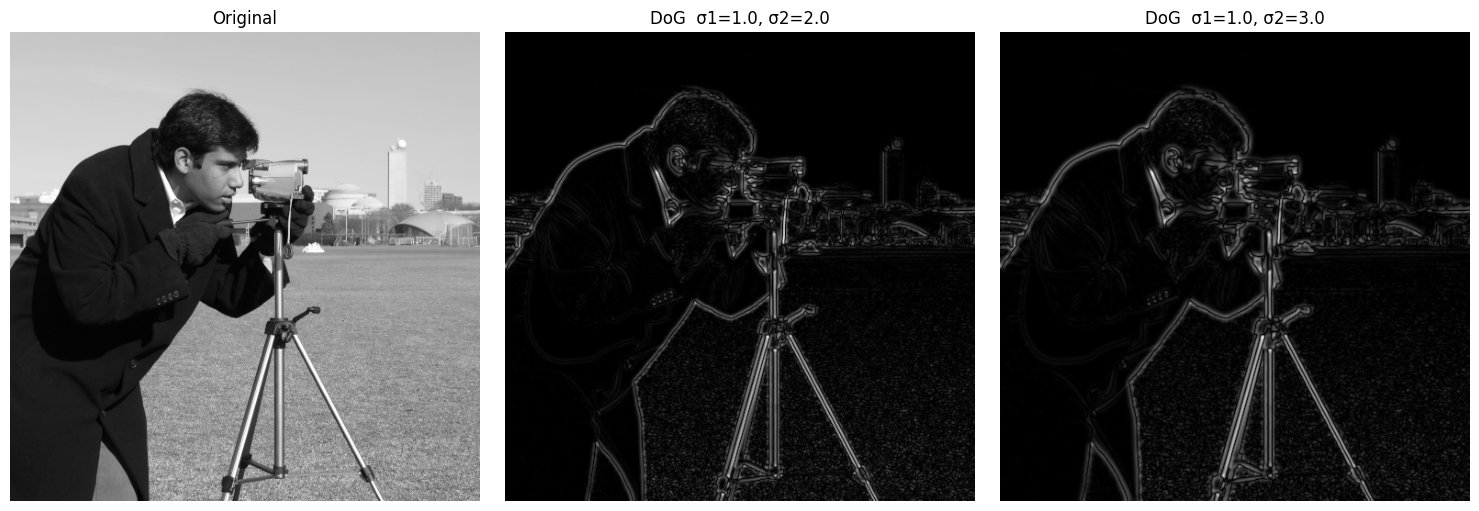

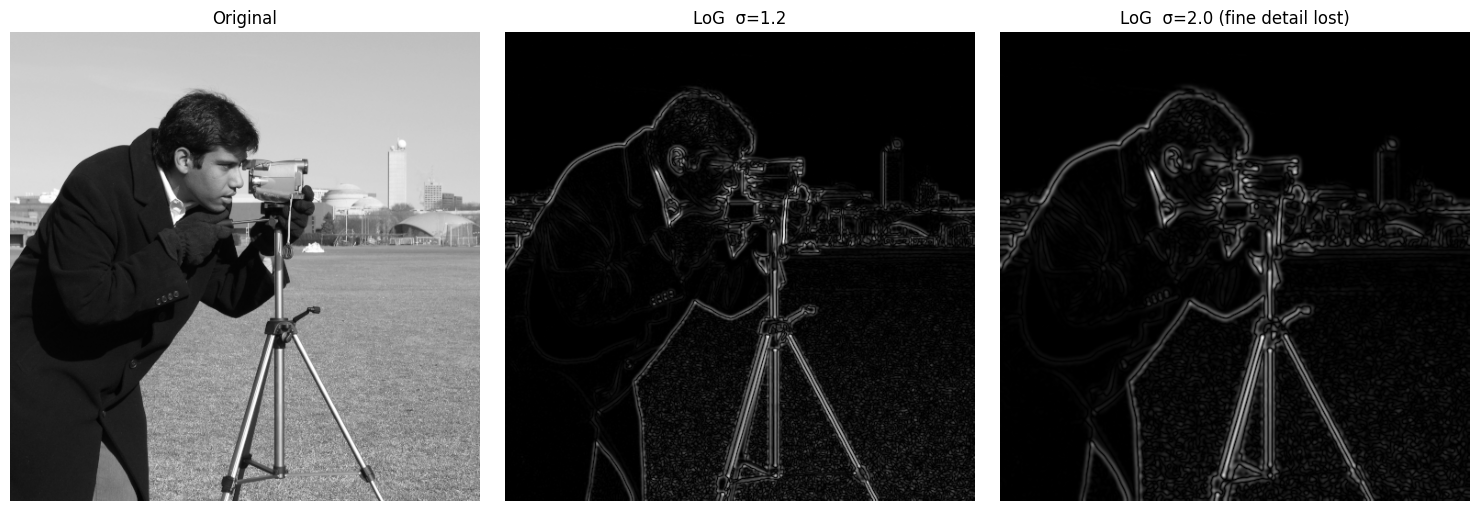

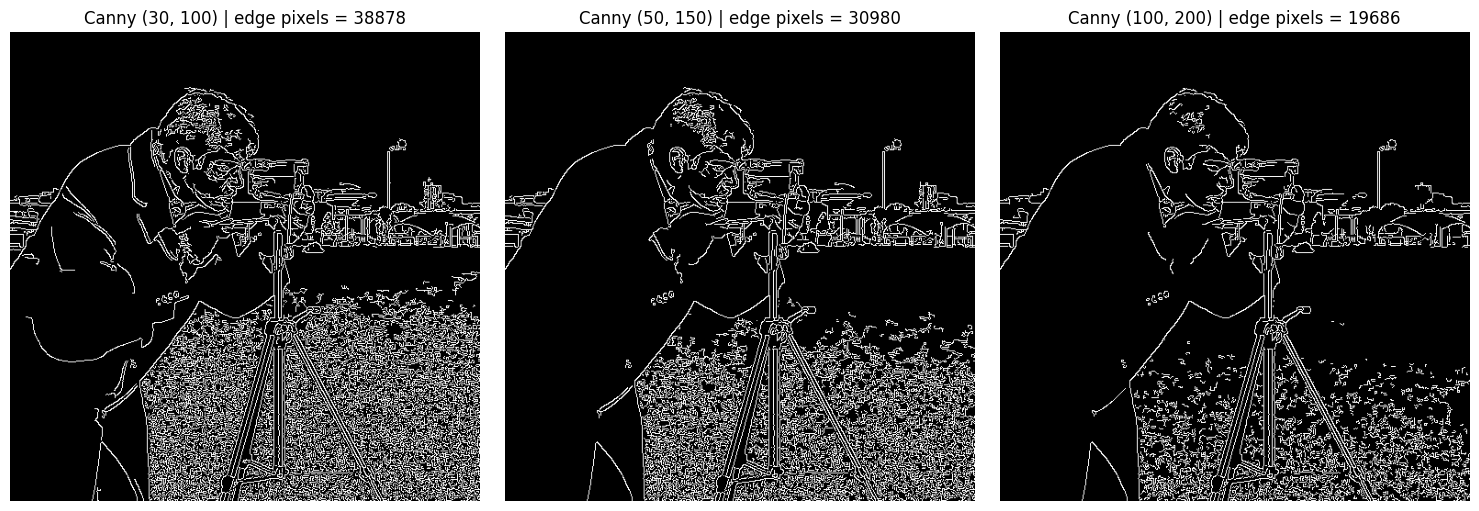

In [3]:
# Task 1: DoG with sigma2 = 2.0 vs 3.0
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(norm8(dog_response(image, 1.0, 2.0)), cmap="gray"); ax[1].set_title("DoG  σ1=1.0, σ2=2.0")
ax[2].imshow(norm8(dog_response(image, 1.0, 3.0)), cmap="gray"); ax[2].set_title("DoG  σ1=1.0, σ2=3.0")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# Task 2: LoG with sigma = 1.2 vs 2.0
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("Original")
ax[1].imshow(norm8(log_response(image, 1.2)), cmap="gray"); ax[1].set_title("LoG  σ=1.2")
ax[2].imshow(norm8(log_response(image, 2.0)), cmap="gray"); ax[2].set_title("LoG  σ=2.0 (fine detail lost)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# Task 3: Canny thresholds
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (lo, hi) in zip(ax, [(30, 100), (50, 150), (100, 200)]):
    c = cv2.Canny(image, lo, hi)
    a.imshow(c, cmap="gray"); a.set_title(f"Canny ({lo}, {hi}) | edge pixels = {np.count_nonzero(c)}"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Quantitative observation table
Edge thickness is estimated as *edge pixels ÷ skeleton pixels* (about 1 means thin, larger means thick). Noise sensitivity is the increase in edge pixels when Gaussian noise (σ = 10) is added. Each response is binarised by keeping the strongest 10 % of its magnitude (Canny is already binary).

        Edge pixels (clean)  Edge pixels (noisy)  Noise increase (%)  Thickness (px/skeleton px)  Connected components (fewer = more continuous)
Method                                                                                                                                          
DoG                   26215                26215                 0.0                        2.17                                            1296
LoG                   26215                26215                 0.0                        1.98                                            1670
Canny                 30980                54396                75.6                        1.20                                             776


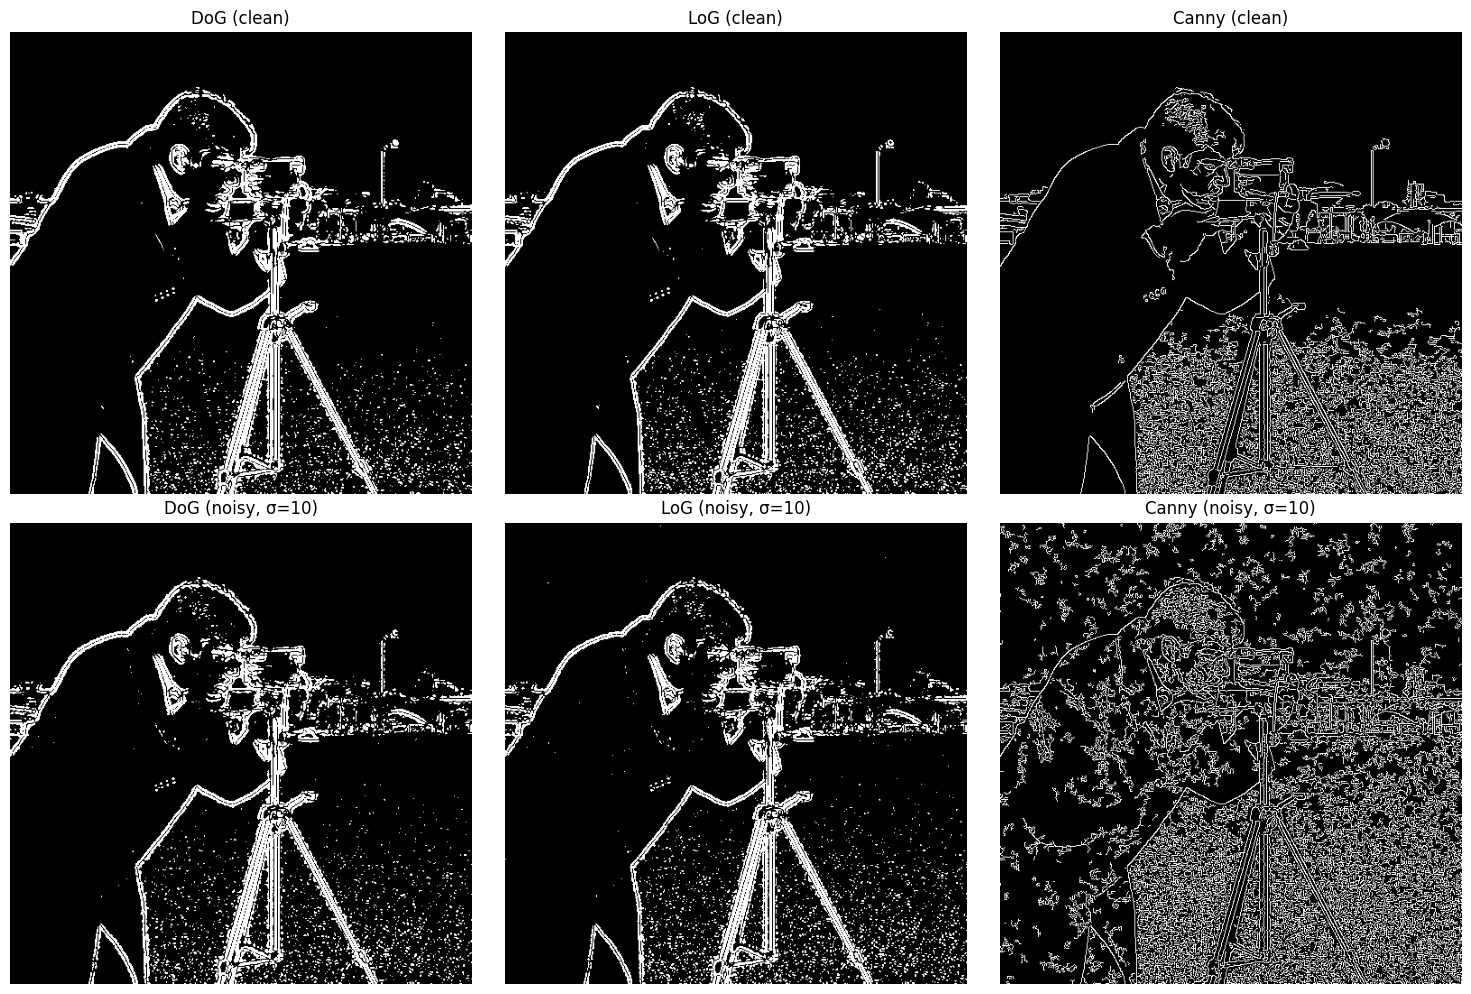

In [4]:
from skimage.morphology import skeletonize
import pandas as pd

def binarise(resp, keep=0.10):
    m = np.abs(resp)
    return (m >= np.quantile(m, 1 - keep)).astype(np.uint8) * 255

def thickness(binary):
    skel = skeletonize(binary > 0)
    return np.count_nonzero(binary) / max(1, np.count_nonzero(skel))

def n_components(binary):
    return cv2.connectedComponents((binary > 0).astype(np.uint8), connectivity=8)[0] - 1

def run_all(img):
    return {
        "DoG":   binarise(dog_response(img, 1.0, 2.0)),
        "LoG":   binarise(log_response(img, 1.2)),
        "Canny": cv2.Canny(img, 50, 150),
    }

rng = np.random.default_rng(0)
noisy = np.clip(image.astype(np.float32) + rng.normal(0, 10, image.shape), 0, 255).astype(np.uint8)

clean_e, noisy_e = run_all(image), run_all(noisy)
rows = []
for name in ["DoG", "LoG", "Canny"]:
    e0, e1 = clean_e[name], noisy_e[name]
    rows.append({
        "Method": name,
        "Edge pixels (clean)": int(np.count_nonzero(e0)),
        "Edge pixels (noisy)": int(np.count_nonzero(e1)),
        "Noise increase (%)": round(100 * (np.count_nonzero(e1) / np.count_nonzero(e0) - 1), 1),
        "Thickness (px/skeleton px)": round(thickness(e0), 2),
        "Connected components (fewer = more continuous)": n_components(e0),
    })
table = pd.DataFrame(rows).set_index("Method")
display(table) if "display" in globals() else print(table.to_string())

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for j, name in enumerate(["DoG", "LoG", "Canny"]):
    ax[0, j].imshow(clean_e[name], cmap="gray"); ax[0, j].set_title(f"{name} (clean)")
    ax[1, j].imshow(noisy_e[name], cmap="gray"); ax[1, j].set_title(f"{name} (noisy, σ=10)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()